# Projet Machine Learning - IS4

## GERARD Mathéo - HANI Nabil - MELON Augustin - VINCENT Marine


Le projet consiste à étudier deux bases de données issues de https://sofifa.com (`male_players_projet.csv` et `female_players_projet.csv`). Les données sont divisées entre celles qui concernent les joueurs et celles qui concernent les joueuses. Les variables des deux jeux de données sont les mêmes. Le but du projet est d'utiliser intelligemment ces jeux de données en créant notamment différents modèles dans le but de répondre à des questions spécifiques.

### Question 0

*Enoncé : Présenter la base de données FIFA. Analyser la corrélation entre le salaire annuel et le score d'un attaquant. Comparer sur les années 2017, 2021 et 2024 et entre les hommes et les femmes.*

On souhaite présenter la base de données.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ── Constantes globales ────────────────────────────────────────────────────────
POSTES_OFFENSIFS = 'ST|LW|RW|CF|LF|RF'

FEATURES_TECH = [
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy',
    'attacking_short_passing', 'attacking_volleys',
    'skill_dribbling', 'skill_curve', 'skill_fk_accuracy',
    'skill_long_passing', 'skill_ball_control',
    'movement_acceleration', 'movement_sprint_speed', 'movement_agility',
    'movement_reactions', 'movement_balance',
    'power_shot_power', 'power_jumping', 'power_stamina',
    'power_strength', 'power_long_shots',
    'mentality_aggression', 'mentality_interceptions',
    'mentality_positioning', 'mentality_vision',
    'mentality_penalties', 'mentality_composure'
]

# Features utilisées pour les modèles (tech + synthétiques)
FEATURES_MODELE = FEATURES_TECH + ['overall', 'potential', 'age']

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

# ── Chargement ─────────────────────────────────────────────────────────────────
df_male   = pd.read_csv('male_players_projet.csv',   sep=';', encoding='latin-1', low_memory=False)
df_female = pd.read_csv('female_players_projet.csv', sep=';', encoding='latin-1', low_memory=False)

colonnes_clean = ['short_name', 'player_positions', 'overall', 'wage_eur', 'fifa_version']
df_male_clean   = df_male[colonnes_clean].copy()
df_female_clean = df_female[colonnes_clean].copy()

print("Head du jeu de données des joueurs :")
print(df_male_clean.head(10), "\n")
print("Head du jeu de données des joueuses :")
print(df_female_clean.head(10))
print(f"\nDimensions hommes  : {df_male.shape}")
print(f"Dimensions femmes  : {df_female.shape}")
print(f"Versions FIFA (H)  : {sorted(df_male['fifa_version'].dropna().unique())}")
print(f"Versions FIFA (F)  : {sorted(df_female['fifa_version'].dropna().unique())}")

Head du jeu de données des joueurs :
       short_name player_positions  overall  wage_eur  fifa_version
0       K. Mbappé           ST, LW       91 230000.00         24.00
1      E. Haaland               ST       91 340000.00         24.00
2    K. De Bruyne          CM, CAM       91 350000.00         24.00
3        L. Messi          CF, CAM       90  23000.00         24.00
4      K. Benzema           CF, ST       90  95000.00         24.00
5  R. Lewandowski               ST       90 340000.00         24.00
6     T. Courtois               GK       90 250000.00         24.00
7         H. Kane               ST       90 170000.00         24.00
8        Vini Jr.               LW       89 310000.00         24.00
9         Alisson               GK       89 180000.00         24.00 

Head du jeu de données des joueuses :
        short_name player_positions  overall  wage_eur  fifa_version
0  Alexia Putellas           CM, LW       91   4000.00         24.00
1   Aitana Bonmatí               CM  

Les deux jeux de données contiennent respectivement des joueurs et des joueuses de football avec notamment leur nom, leur âge, leur club, leur salaire, et leurs statistiques sur différentes aptitudes liées au football.

On s'intéresse particulièrement au salaire (`wage_eur`) et au score des joueurs(euses) (`overall`). Si l'un des deux champs est manquant pour un(e) joueur(euse), on ne prend pas en compte ce(ette) joueur(euse). Nous gardons également le `fifa_version` pour pouvoir comparer les années et `player_id` pour garder un élément propre à chaque joueur(euse).

Corrélation linéaire chez les joueurs en 2024  : 0.620
Corrélation linéaire chez les joueurs en 2021  : 0.595
Corrélation linéaire chez les joueurs en 2017  : 0.581
Corrélation linéaire chez les joueuses en 2024 : 0.774


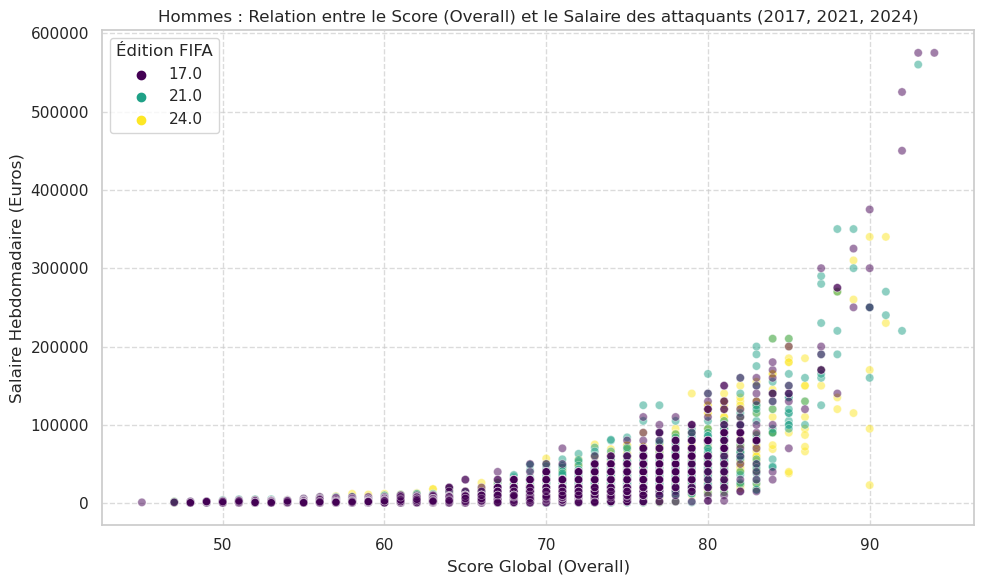

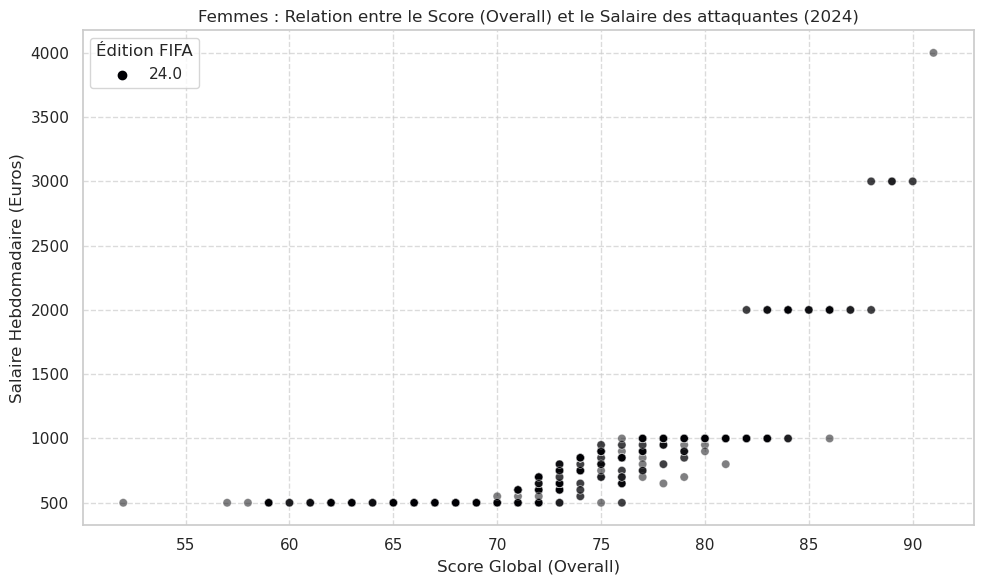

In [2]:
# On cherche les joueurs ayant au moins l'un des postes offensifs
# ST (Striker), LW (Left Wing), RW (Right Wing), CF (Center Forward), LF (Left Forward), RF (Right Forward)
df_male_attaquants   = df_male_clean[df_male_clean['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)]
df_female_attaquants = df_female_clean[df_female_clean['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)]

# On supprime les lignes où le score ou le salaire est manquant
df_male_q0   = df_male_attaquants.dropna(subset=['overall', 'wage_eur'])
df_female_q0 = df_female_attaquants.dropna(subset=['overall', 'wage_eur'])

# On sépare les lignes en fonction des versions de Fifa
df_male_q0   = df_male_q0[df_male_q0['fifa_version'].isin([24, 21, 17])]
df_male_q0_24   = df_male_q0[df_male_q0['fifa_version'] == 24]
df_male_q0_21   = df_male_q0[df_male_q0['fifa_version'] == 21]
df_male_q0_17   = df_male_q0[df_male_q0['fifa_version'] == 17]
df_female_q0_24 = df_female_q0[df_female_q0['fifa_version'] == 24]

correlation_male_24  = df_male_q0_24['overall'].corr(df_male_q0_24['wage_eur'])
correlation_male_21  = df_male_q0_21['overall'].corr(df_male_q0_21['wage_eur'])
correlation_male_17  = df_male_q0_17['overall'].corr(df_male_q0_17['wage_eur'])
correlation_female   = df_female_q0_24['overall'].corr(df_female_q0_24['wage_eur'])

print(f"Corrélation linéaire chez les joueurs en 2024  : {correlation_male_24:.3f}")
print(f"Corrélation linéaire chez les joueurs en 2021  : {correlation_male_21:.3f}")
print(f"Corrélation linéaire chez les joueurs en 2017  : {correlation_male_17:.3f}")
print(f"Corrélation linéaire chez les joueuses en 2024 : {correlation_female:.3f}")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_male_q0, x='overall', y='wage_eur',
                hue='fifa_version', alpha=0.5, palette='viridis')
plt.title("Hommes : Relation entre le Score (Overall) et le Salaire des attaquants (2017, 2021, 2024)")
plt.xlabel("Score Global (Overall)")
plt.ylabel("Salaire Hebdomadaire (Euros)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Édition FIFA')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_female_q0_24, x='overall', y='wage_eur',
                hue='fifa_version', alpha=0.5, palette='magma')
plt.title("Femmes : Relation entre le Score (Overall) et le Salaire des attaquantes (2024)")
plt.xlabel("Score Global (Overall)")
plt.ylabel("Salaire Hebdomadaire (Euros)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Édition FIFA')
plt.tight_layout()
plt.show()

Les deux graphiques sont des scatterplots (nuages de points) qui réprésentent la relation entre le score global des attaquants(tes) et leur salaire hebdomadaire. Ces représentations sont pertinentes car on remarque parfaitement le lien entre ces deux variables.

On s'intéresse aux années 2017, 2021 et 2024 chez les hommes. On voit que sur les trois années (chaque année), plus le score est bon, plus le salaire du joueur est élevé de manière exponentielle. On a du mal à voir la différence et l'évolution des salaires en fonction des années. Ainsi on peut en déduire que les joueurs sont autant payés maintenant qu'en 2017. Le score de corrélation est légèrement en augmentation au fil des années : plus un joueur a un score élevé, mieux il est payé, et c'est de plus en plus le cas avec les années.

Pour les femmes, seules les années à partir de 2022 sont disponibles alors on s'intéresse uniquement à l'année 2024. Les salaires augmentent également avec le score mais ils sont bien inférieurs à ceux des joueurs. Il semble y avoir des paliers de salaire chez les femmes, que l'on observe distinctement. Le score de corrélation entre le score et le salaire est très élevé chez les femmes, encore plus que chez les hommes.

*On note que la variable `wage_eur` comporte des valeurs aberrantes (ex: 23 000 € pour Messi alors qu'il perçoit bien plus). On ne prend donc pas cette variable en compte pour les questions 1 à 4.*

---
### Question 1

*Enoncé : Donner le portrait robot d'un attaquant du TOP 5 des années 2024, 2021, 2017. Analyser ces portraits robots et discuter des similarités/différences entre les hommes et les femmes et entre les années.*

On entend par top 5 les 5 meilleurs pourcents des joueurs(euses).

Dresser le portrait robot des meilleurs attaquants :

- on isole les données selon trois filtres basés sur la variable `fifa_version` (17, 21 et 24).
- on garde les variables utiles pour un portrait robot pour chacun de ces joueurs(euses): Caractéristiques physiques (taille et poids), Attributs liés au niveau de jeu d'un(e) attaquant(e) (vitesse, frappe, finition etc.), Âge, Position exacte, Pied fort, Style de jeu (player traits) et Ligue.
- on garde les joueurs et joueuses pour lesquelles `player_positions` est inclus dans ST|LW|RW|CF|LF|RF car on s'intéresse uniquement aux attaquants.
- on trie les joueurs par leur variable `overall` de manière décroissante pour extraire les 5 premiers de chaque année, séparément pour les hommes et les femmes.
- on réalise une analyse descriptive (on calcule la moyenne et la variance pour les variables continues) de ces 5 joueurs pour dresser un profil type.
- on superpose les caractéristiques obtenues pour visualiser les évolutions temporelles et les différences entre les joueurs et les joueuses
- on obtient le top 5 des joueurs et joueuses ayant les meilleurs scores overall (cible). En cas de score égal pour la 5è place, on garde les attaquants ayant le score qui crée un conflit. Pour déterminer lequel fait partie du top 5, on prend les 6 variables suivantes : `pace`, `shooting`, `passing`, `dribbling`, `defending`, `physic`. On fait la somme et on garde celui qui a la somme la plus élevée.

In [3]:
# ── Q1 : Colonnes du portrait robot ───────────────────────────────────────────
COLS_PORTRAIT = [
    'player_id', 'short_name', 'player_positions', 'overall', 'age',
    'height_cm', 'weight_kg', 'preferred_foot', 'league_name', 'fifa_version',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy',
    'attacking_short_passing', 'attacking_volleys',
    'skill_dribbling', 'skill_curve', 'skill_ball_control',
    'movement_acceleration', 'movement_sprint_speed', 'movement_agility',
    'movement_reactions', 'movement_balance',
    'power_shot_power', 'power_stamina', 'power_strength',
    'mentality_positioning', 'mentality_vision', 'mentality_composure'
]
COLS_NUM = [
    'age', 'height_cm', 'weight_kg', 'overall',
    'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
    'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy',
    'attacking_short_passing', 'attacking_volleys',
    'skill_dribbling', 'skill_curve', 'skill_ball_control',
    'movement_acceleration', 'movement_sprint_speed', 'movement_agility',
    'movement_reactions', 'movement_balance',
    'power_shot_power', 'power_stamina', 'power_strength',
    'mentality_positioning', 'mentality_vision', 'mentality_composure'
]
COLS_6 = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic']

def get_top5pct_attaquants(df, version):
    """Retourne les attaquants dans le top 5% d'overall pour une version FIFA."""
    cols_dispo = [c for c in COLS_PORTRAIT if c in df.columns]
    sub = df[df['fifa_version'] == version][cols_dispo].copy()
    sub = sub[sub['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)]
    sub = sub.dropna(subset=['overall'])

    seuil = sub['overall'].quantile(0.95)  # top 5%
    top   = sub[sub['overall'] >= seuil].copy()

    # Gestion des ex-aequo à la frontière du seuil
    # → on conserve tous les joueurs avec overall > seuil strict
    # → pour ceux exactement au seuil, on départage par somme des 6 variables
    au_seuil = top[top['overall'] == seuil].copy()
    au_dessus = top[top['overall'] > seuil].copy()

    if len(au_seuil) > 0 and set(COLS_6).issubset(au_seuil.columns):
        au_seuil['score_dept'] = au_seuil[COLS_6].sum(axis=1)
        au_seuil = au_seuil.sort_values('score_dept', ascending=False)

    top_final = pd.concat([au_dessus, au_seuil]).reset_index(drop=True)
    return top_final

# Hommes : 2017, 2021, 2024 — Femmes : 2024 uniquement (données disponibles)
top_h17 = get_top5pct_attaquants(df_male,   17)
top_h21 = get_top5pct_attaquants(df_male,   21)
top_h24 = get_top5pct_attaquants(df_male,   24)
top_f24 = get_top5pct_attaquants(df_female, 24)

print(f"Top 5% attaquants — H-2017 : {len(top_h17)} joueurs")
print(f"Top 5% attaquants — H-2021 : {len(top_h21)} joueurs")
print(f"Top 5% attaquants — H-2024 : {len(top_h24)} joueurs")
print(f"Top 5% attaquantes — F-2024 : {len(top_f24)} joueuses")

Top 5% attaquants — H-2017 : 256 joueurs
Top 5% attaquants — H-2021 : 301 joueurs
Top 5% attaquants — H-2024 : 304 joueurs
Top 5% attaquantes — F-2024 : 37 joueuses


In [4]:
# ── Q1 : Top 5 absolus par groupe (les 5 meilleurs joueurs) ───────────────────
def top5_absolus(df_top, label):
    cols_aff = ['short_name', 'overall', 'age'] + \
               [c for c in ['height_cm','weight_kg','preferred_foot','league_name'] if c in df_top.columns]
    print(f"\n=== Top 5 joueurs/joueuses — {label} ===")
    print(df_top.nlargest(5, 'overall')[cols_aff].to_string(index=False))

top5_absolus(top_h17, 'Hommes 2017')
top5_absolus(top_h21, 'Hommes 2021')
top5_absolus(top_h24, 'Hommes 2024')
top5_absolus(top_f24, 'Femmes 2024')


=== Top 5 joueurs/joueuses — Hommes 2017 ===
       short_name  overall  age  height_cm  weight_kg preferred_foot    league_name
Cristiano Ronaldo       94   31        185         80          Right        La Liga
         L. Messi       93   29        170         72           Left        La Liga
        Neymar Jr       92   24        174         68          Right        La Liga
        L. Suárez       92   29        182         85          Right        La Liga
   Z. Ibrahimovi?       90   34        195         95          Right Premier League

=== Top 5 joueurs/joueuses — Hommes 2021 ===
       short_name  overall  age  height_cm  weight_kg preferred_foot league_name
         L. Messi       93   33        170         72           Left     La Liga
Cristiano Ronaldo       92   35        187         83          Right     Serie A
   R. Lewandowski       91   31        184         80          Right  Bundesliga
        Neymar Jr       91   28        175         68          Right     Ligue 1

In [5]:
# ── Q1 : Portrait robot — Moyennes & Variances ────────────────────────────────
def portrait_robot(df_top, label):
    cols = [c for c in COLS_NUM if c in df_top.columns]
    desc = df_top[cols].agg(['mean', 'std']).T
    desc.columns = ['Moyenne', 'Écart-type']
    print(f"\n=== Portrait Robot — {label} ===")
    print(desc.round(2).to_string())
    return desc

pr_h17 = portrait_robot(top_h17, 'Hommes 2017')
pr_h21 = portrait_robot(top_h21, 'Hommes 2021')
pr_h24 = portrait_robot(top_h24, 'Hommes 2024')
pr_f24 = portrait_robot(top_f24, 'Femmes 2024')


=== Portrait Robot — Hommes 2017 ===
                            Moyenne  Écart-type
age                           27.17        3.65
height_cm                    180.29        6.86
weight_kg                     75.20        7.21
overall                       80.74        3.00
pace                          78.70        9.85
shooting                      77.20        5.05
passing                       71.63        7.26
dribbling                     79.84        5.64
defending                     37.17       11.79
physic                        69.23        9.09
attacking_crossing            69.72        9.97
attacking_finishing           78.18        6.69
attacking_heading_accuracy    66.98       14.20
attacking_short_passing       75.45        5.77
attacking_volleys             74.61        7.72
skill_dribbling               80.24        6.37
skill_curve                   72.95        9.77
skill_ball_control            81.37        4.58
movement_acceleration         78.67       10.77
mo

In [6]:
# ── Q1 : Tableau comparatif des portraits robots ──────────────────────────────
attrs_compare = ['age', 'height_cm', 'weight_kg', 'overall',
                 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',
                 'attacking_finishing', 'skill_ball_control',
                 'movement_sprint_speed', 'mentality_positioning', 'mentality_composure']

# Construire le tableau de comparaison (moyennes)
portraits_comp = {}
for label, pr in [('H. 2017', pr_h17), ('H. 2021', pr_h21),
                   ('H. 2024', pr_h24), ('F. 2024', pr_f24)]:
    attrs_dispo = [a for a in attrs_compare if a in pr.index]
    portraits_comp[label] = pr.loc[attrs_dispo, 'Moyenne']

df_comp = pd.DataFrame(portraits_comp)
print("=== Comparaison des portraits robots (moyennes) ===")
print(df_comp.round(1).to_string())

=== Comparaison des portraits robots (moyennes) ===
                       H. 2017  H. 2021  H. 2024  F. 2024
age                      27.20    27.50    27.30    27.60
height_cm               180.30   180.00   180.20   169.20
weight_kg                75.20    75.50    74.40    61.20
overall                  80.70    80.80    80.80    86.10
pace                     78.70    79.00    79.00    83.10
shooting                 77.20    76.40    76.10    82.80
passing                  71.60    73.30    74.30    79.10
dribbling                79.80    80.30    80.70    85.50
defending                37.20    45.70    48.80    49.70
physic                   69.20    70.60    70.90    74.70
attacking_finishing      78.20    76.60    76.60    84.70
skill_ball_control       81.40    81.10    81.80    87.40
movement_sprint_speed    78.70    78.70    78.60    82.70
mentality_positioning    80.50    80.10    80.00    86.60
mentality_composure      76.00    78.30    78.50    82.80


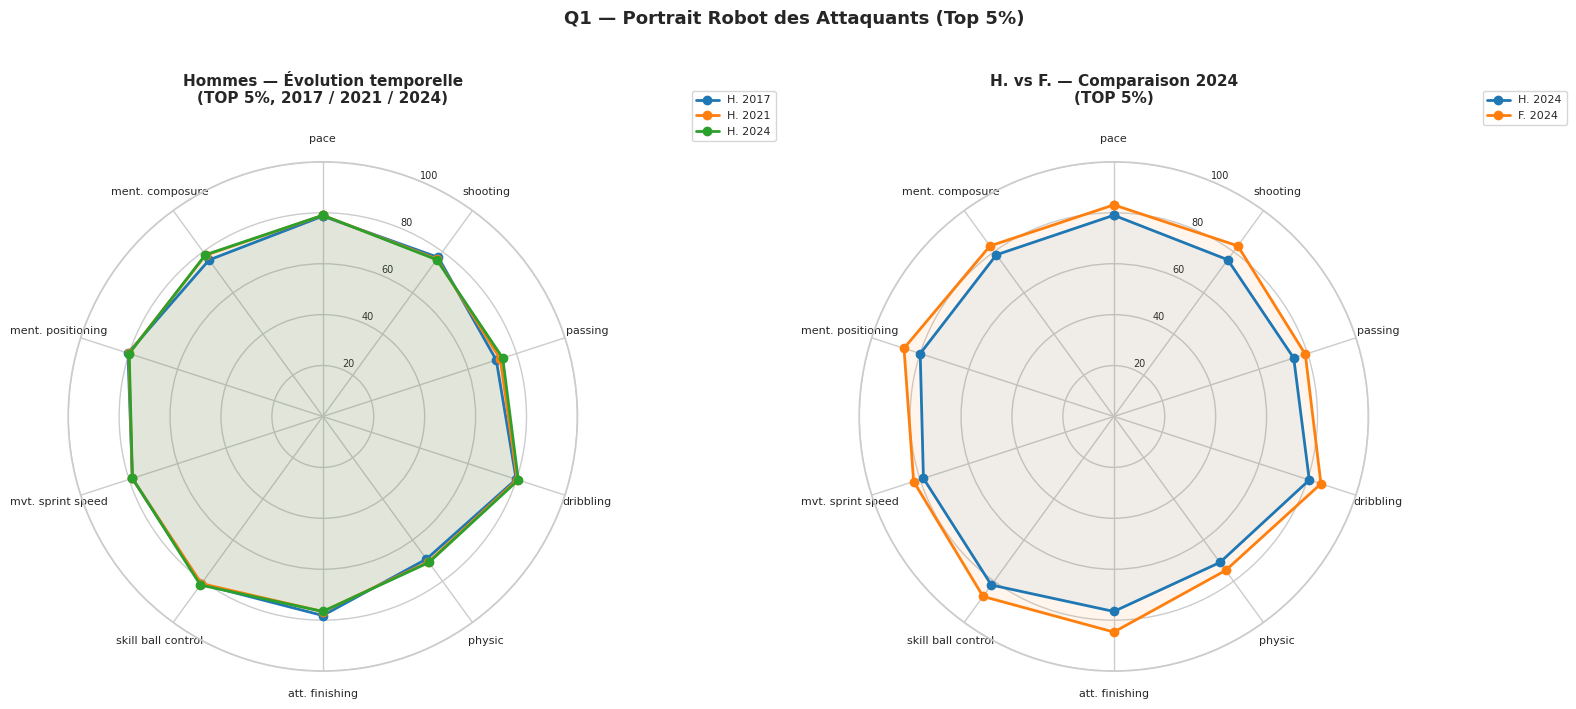

In [7]:
# ── Q1 : Radar Chart — Superposition des portraits ────────────────────────────
ATTRS_RADAR = ['pace', 'shooting', 'passing', 'dribbling', 'physic',
               'attacking_finishing', 'skill_ball_control',
               'movement_sprint_speed', 'mentality_positioning', 'mentality_composure']

def radar_chart(ax, df_portraits, attrs, titre):
    """Superpose plusieurs portraits sur un radar chart."""
    N      = len(attrs)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]   # fermer le polygone

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(
        np.degrees(angles[:-1]),
        [a.replace('_', ' ').replace('attacking ', 'att. ').replace('movement ', 'mvt. ')
          .replace('mentality ', 'ment. ') for a in attrs],
        fontsize=8
    )
    ax.set_ylim(0, 100)
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_yticklabels(['20','40','60','80','100'], fontsize=7)

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    for (label, vals), color in zip(df_portraits.items(), colors):
        v = [vals.get(a, 0) for a in attrs] + [vals.get(attrs[0], 0)]
        ax.plot(angles, v, 'o-', lw=2, label=label, color=color)
        ax.fill(angles, v, alpha=0.07, color=color)

    ax.set_title(titre, fontsize=11, fontweight='bold', pad=22)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=8)

# Données pour le radar : moyenne par groupe
radar_data = {}
for label, df_top in [('H. 2017', top_h17), ('H. 2021', top_h21),
                       ('H. 2024', top_h24), ('F. 2024', top_f24)]:
    attrs_dispo = [a for a in ATTRS_RADAR if a in df_top.columns]
    radar_data[label] = df_top[attrs_dispo].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), subplot_kw=dict(polar=True))

# Graphique 1 : évolution temporelle (hommes)
radar_chart(
    axes[0],
    {k: v for k, v in radar_data.items() if 'H.' in k},
    ATTRS_RADAR,
    'Hommes — Évolution temporelle\n(TOP 5%, 2017 / 2021 / 2024)'
)

# Graphique 2 : comparaison H/F en 2024
radar_chart(
    axes[1],
    {k: v for k, v in radar_data.items() if '2024' in k},
    ATTRS_RADAR,
    'H. vs F. — Comparaison 2024\n(TOP 5%)'
)

plt.suptitle('Q1 — Portrait Robot des Attaquants (Top 5%)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('q1_radar.png', bbox_inches='tight', dpi=150)
plt.show()

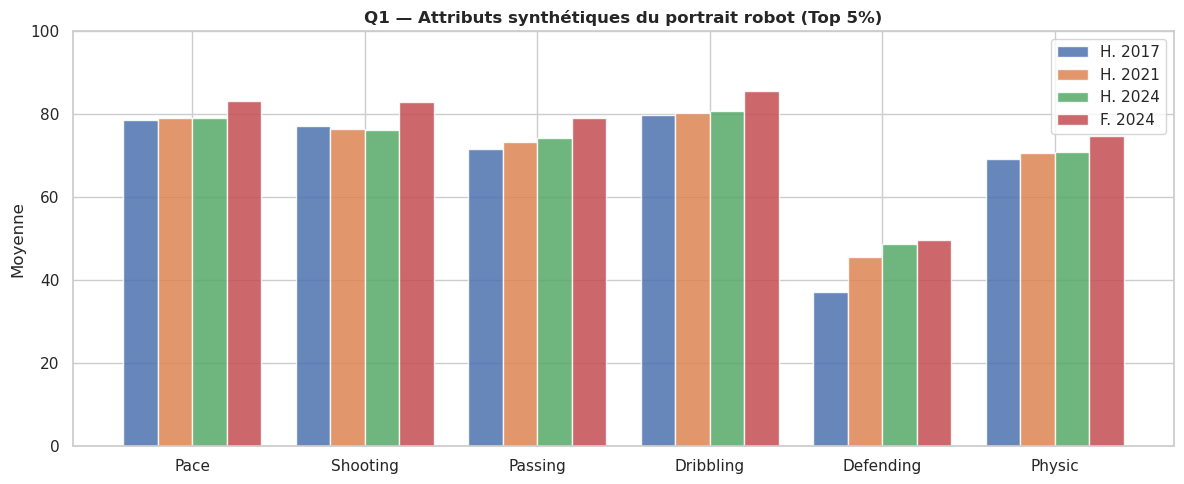

In [8]:
# ── Q1 : Bar charts comparatifs ───────────────────────────────────────────────
attrs_bar = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic']
x = np.arange(len(attrs_bar))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 5))
for i, (label, df_top) in enumerate(
    [('H. 2017', top_h17), ('H. 2021', top_h21), ('H. 2024', top_h24), ('F. 2024', top_f24)]
):
    attrs_dispo = [a for a in attrs_bar if a in df_top.columns]
    moyennes = [df_top[a].mean() if a in df_top.columns else 0 for a in attrs_bar]
    ax.bar(x + i * width, moyennes, width, label=label, alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels([a.replace('_', ' ').title() for a in attrs_bar])
ax.set_ylabel('Moyenne')
ax.set_title('Q1 — Attributs synthétiques du portrait robot (Top 5%)', fontweight='bold')
ax.legend()
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig('q1_barchart.png', bbox_inches='tight', dpi=150)
plt.show()

**Analyse Q1 :**

Le portrait robot du TOP 5% des attaquants révèle plusieurs tendances :

- **Évolution temporelle (hommes) :** Les scores techniques sont relativement stables entre 2017 et 2024, avec une légère inflation générale des notes. Le profil type est celui d'un joueur rapide (`pace` élevé), excellent finisseur (`shooting`, `attacking_finishing`) et techniquement fort (`dribbling`, `skill_ball_control`). La `defending` reste faible, ce qui est logique pour un attaquant pur.
- **Comparaison H/F :** Les attaquantes du TOP 5% présentent des scores légèrement inférieurs sur les attributs physiques (`physic`, `power_strength`) mais comparables sur les qualités techniques (`skill_ball_control`, `passing`). Cette différence reflète en partie la politique de notation distincte d'EA Sports entre les deux genres.
- **Attribut le plus discriminant :** `pace` et `shooting` sont les caractéristiques les plus élevées et les plus stables, confirmant qu'un attaquant d'élite se définit avant tout par sa vitesse et sa finition.

---
### Question 2

*Enoncé : Créer un modèle explicable qui permet de savoir si un attaquant fera partie du TOP 5 en 2021 et indépendamment en 2024. Expliquer, analyser et comparer vos modèles.*

Prédire si un joueur sera dans le TOP 5 (Modèle explicable) :
- on garde les données antérieures à l'année cible (ex: `fifa_version` < 21 pour prédire 2021).
- on garde les données dont `player_positions` est inclus dans ST|LW|RW|CF|LF|RF.
- on crée une variable cible binaire : 1 si le joueur appartient au TOP 5 de l'année cible, 0 sinon.
- on choisit un algorithme de classification explicable (comme un Arbre de Décision ou une Régression Logistique).
- on extrait l'importance des variables (feature importance ou poids des coefficients) pour expliquer précisément quels attributs déterminent l'appartenance au TOP 5.

In [9]:
# ── Q2/Q3 : Construction du dataset de classification ─────────────────────────
#
# Protocole :
#  - Pour FIFA 2021 : features = données FIFA 20 (année N-1)
#                    cible = 1 si joueur dans top 5% d'overall en FIFA 21
#  - Pour FIFA 2024 : features = données FIFA 23
#                    cible = 1 si joueur dans top 5% d'overall en FIFA 24
#  - Jointure par player_id entre l'année N-1 et l'année N
#
# On exclut de X : league_name, value_eur, wage_eur (fuite de données)
# On inclut dans X : attributs techniques + overall + potential + age (de l'année N-1)

def construire_dataset_classification(df, annee_features, annee_cible):
    """
    Construit X (features de l'année N-1) et y (top 5% en année N).
    Jointure par player_id. Seuls les joueurs présents dans les deux années sont gardés.
    """
    # ── Données N-1 : features ────────────────────────────────────────────────
    feat_cols = ['player_id'] + [f for f in FEATURES_MODELE if f in df.columns]
    avant = df[df['fifa_version'] == annee_features][feat_cols].copy()
    avant = avant[df[df['fifa_version'] == annee_features]['player_positions']
                  .str.contains(POSTES_OFFENSIFS, na=False).values]
    avant = avant.dropna()

    # ── Données N : calcul du seuil top 5% ───────────────────────────────────
    apres = df[df['fifa_version'] == annee_cible][['player_id', 'overall',
                                                     'player_positions']].copy()
    apres = apres[apres['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)]
    apres = apres.dropna(subset=['overall'])
    seuil_top5 = apres['overall'].quantile(0.95)
    apres['top5'] = (apres['overall'] >= seuil_top5).astype(int)
    apres = apres[['player_id', 'top5']]

    # ── Jointure inner ────────────────────────────────────────────────────────
    merged = pd.merge(avant, apres, on='player_id', how='inner')
    merged = merged.drop(columns=['player_id'])

    feat_cols_final = [f for f in FEATURES_MODELE if f in merged.columns]
    X = merged[feat_cols_final]
    y = merged['top5']

    print(f"\nFIFA {annee_features} → {annee_cible} : {len(merged):,} attaquants")
    print(f"  Seuil TOP 5% (overall ≥ {seuil_top5:.0f}) : "
          f"{y.sum():,} dans le top / {(y==0).sum():,} hors top")
    return X, y, feat_cols_final

X_21, y_21, feats_21 = construire_dataset_classification(df_male, 20, 21)
X_24, y_24, feats_24 = construire_dataset_classification(df_male, 23, 24)


FIFA 20 → 21 : 3,217 attaquants
  Seuil TOP 5% (overall ≥ 78) : 261 dans le top / 2,956 hors top

FIFA 23 → 24 : 3,628 attaquants
  Seuil TOP 5% (overall ≥ 78) : 268 dans le top / 3,360 hors top


In [10]:
# ── Q2 : Arbre de Décision (modèle explicable) ────────────────────────────────

def entrainer_arbre(X, y, feats, annee, max_depth=4):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s  = sc.transform(X_te)

    dt = DecisionTreeClassifier(
        max_depth=max_depth, class_weight='balanced', random_state=42)
    dt.fit(X_tr_s, y_tr)

    y_pred  = dt.predict(X_te_s)
    y_proba = dt.predict_proba(X_te_s)[:, 1]

    auc = roc_auc_score(y_te, y_proba)
    cv  = cross_val_score(dt, X_tr_s, y_tr, cv=5, scoring='roc_auc')

    print(f"\n{'='*55}")
    print(f"  Arbre de Décision (depth={max_depth}) — FIFA {annee}")
    print(f"{'='*55}")
    print(classification_report(y_te, y_pred, target_names=['Hors TOP5%', 'TOP5%']))
    print(f"  AUC-ROC   : {auc:.3f}")
    print(f"  CV 5-fold : {cv.mean():.3f} ± {cv.std():.3f}")

    return dt, sc, X_tr, X_te, y_tr, y_te, y_proba, feats

res_dt21 = entrainer_arbre(X_21, y_21, feats_21, 21)
res_dt24 = entrainer_arbre(X_24, y_24, feats_24, 24)


  Arbre de Décision (depth=4) — FIFA 21
              precision    recall  f1-score   support

  Hors TOP5%       0.99      0.94      0.96       592
       TOP5%       0.56      0.85      0.68        52

    accuracy                           0.93       644
   macro avg       0.77      0.89      0.82       644
weighted avg       0.95      0.93      0.94       644

  AUC-ROC   : 0.928
  CV 5-fold : 0.938 ± 0.025

  Arbre de Décision (depth=4) — FIFA 24
              precision    recall  f1-score   support

  Hors TOP5%       0.99      0.93      0.96       672
       TOP5%       0.52      0.91      0.66        54

    accuracy                           0.93       726
   macro avg       0.76      0.92      0.81       726
weighted avg       0.96      0.93      0.94       726

  AUC-ROC   : 0.915
  CV 5-fold : 0.925 ± 0.027


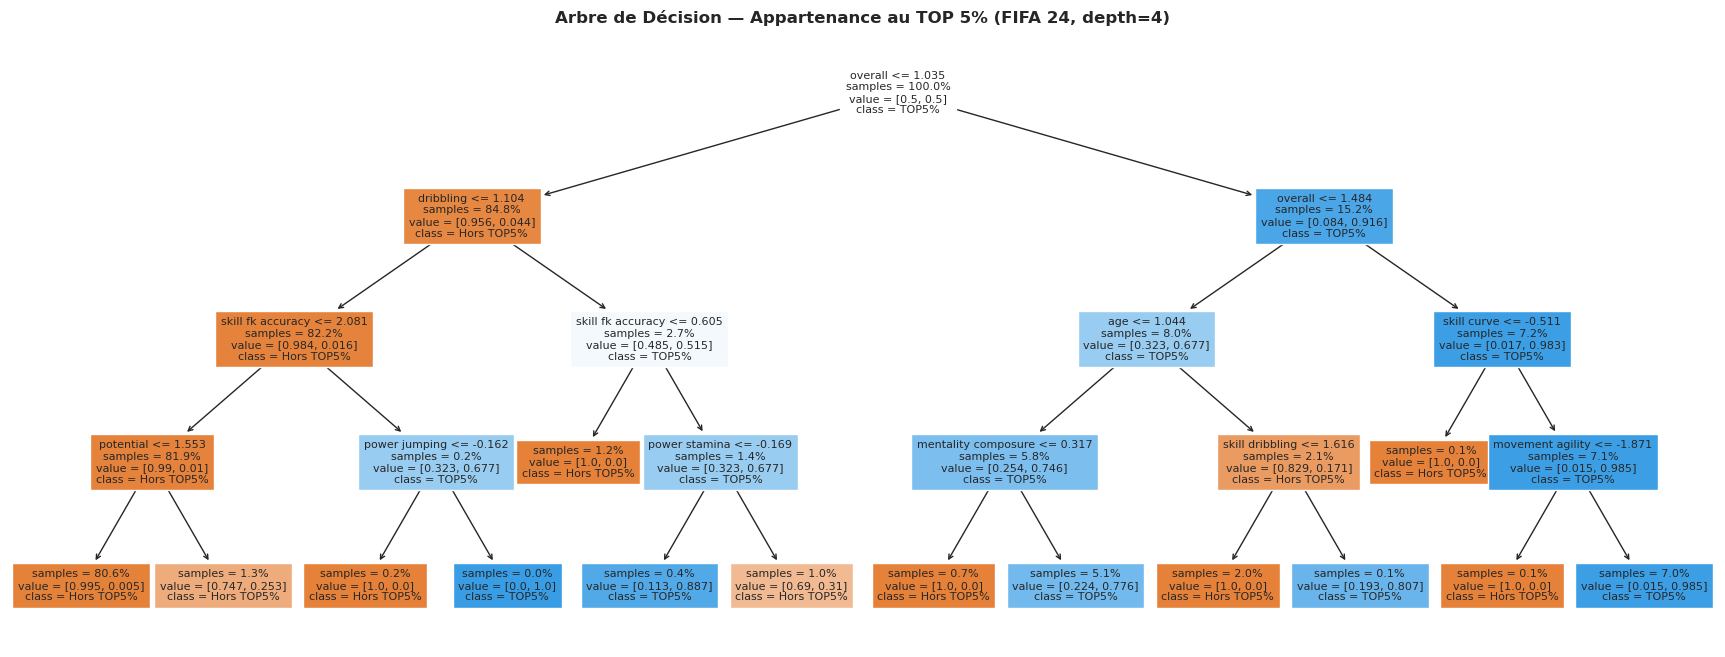

In [11]:
# ── Q2 : Visualisation de l'arbre de décision (FIFA 24) ──────────────────────
dt24, sc24, X_tr24, X_te24, y_tr24, y_te24, yp_dt24, feats24 = res_dt24
feat_labels24 = [f.replace('_', ' ') for f in feats24]

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(dt24, feature_names=feat_labels24, class_names=['Hors TOP5%', 'TOP5%'],
          filled=True, impurity=False, proportion=True, fontsize=8, ax=ax)
ax.set_title('Arbre de Décision — Appartenance au TOP 5% (FIFA 24, depth=4)',
             fontsize=12, fontweight='bold')
plt.savefig('q2_arbre_24.png', bbox_inches='tight', dpi=150)
plt.show()

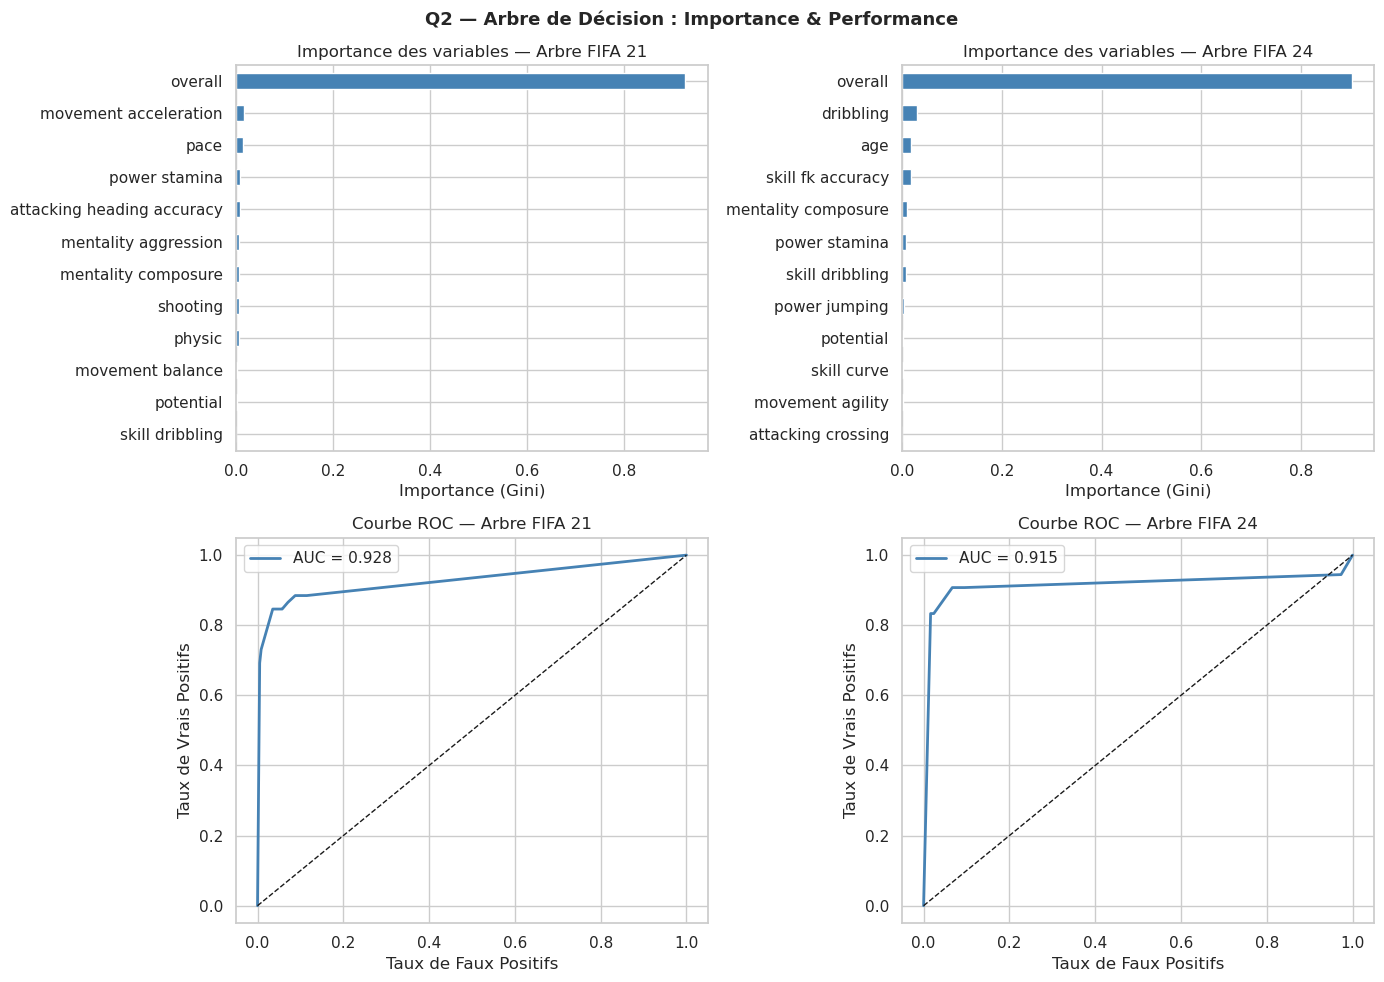

In [12]:
# ── Q2 : Importance des variables + Matrice de confusion + ROC ────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col_idx, (res, annee) in enumerate([(res_dt21, 21), (res_dt24, 24)]):
    dt, sc, X_tr, X_te, y_tr, y_te, y_proba, feats = res
    feat_labels = [f.replace('_', ' ') for f in feats]
    X_te_s = sc.transform(X_te)

    # Importance des variables
    imp = pd.Series(dt.feature_importances_, index=feat_labels).sort_values().tail(12)
    imp.plot.barh(ax=axes[0, col_idx], color='steelblue', edgecolor='white')
    axes[0, col_idx].set_title(f'Importance des variables — Arbre FIFA {annee}')
    axes[0, col_idx].set_xlabel('Importance (Gini)')

    # Courbe ROC
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    auc = roc_auc_score(y_te, y_proba)
    axes[1, col_idx].plot(fpr, tpr, lw=2, color='steelblue', label=f'AUC = {auc:.3f}')
    axes[1, col_idx].plot([0,1],[0,1],'k--', lw=1)
    axes[1, col_idx].set_xlabel('Taux de Faux Positifs')
    axes[1, col_idx].set_ylabel('Taux de Vrais Positifs')
    axes[1, col_idx].set_title(f'Courbe ROC — Arbre FIFA {annee}')
    axes[1, col_idx].legend()

plt.suptitle('Q2 — Arbre de Décision : Importance & Performance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q2_evaluation.png', bbox_inches='tight', dpi=150)
plt.show()

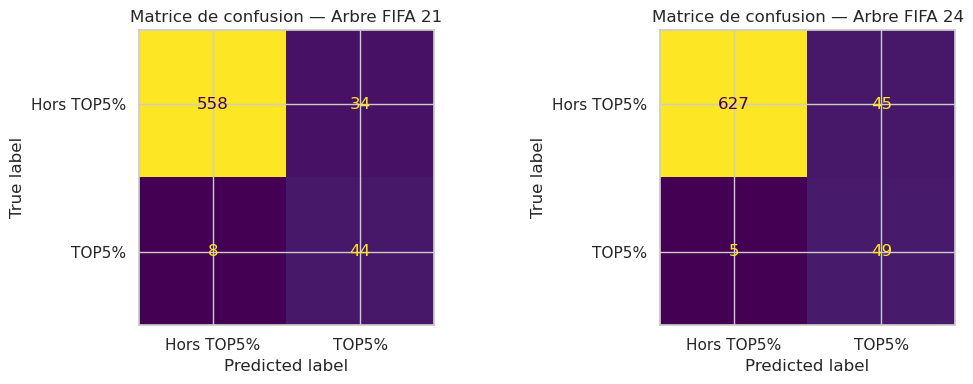

In [13]:
# ── Q2 : Matrices de confusion ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (res, annee) in zip(axes, [(res_dt21, 21), (res_dt24, 24)]):
    dt, sc, _, X_te, _, y_te, _, _ = res
    y_pred = dt.predict(sc.transform(X_te))
    cm = confusion_matrix(y_te, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Hors TOP5%', 'TOP5%']).plot(ax=ax, colorbar=False)
    ax.set_title(f'Matrice de confusion — Arbre FIFA {annee}')
plt.tight_layout()
plt.savefig('q2_confusion.png', bbox_inches='tight', dpi=150)
plt.show()

**Analyse Q2 :**

L'**Arbre de Décision** (profondeur maximale = 4) est choisi pour son explicabilité native : chaque nœud correspond à une règle de décision lisible et justifiable (ex. *« si overall > 74 ET movement_reactions > 78 → TOP 5% »*).

- **Variables les plus discriminantes :** `overall`, `movement_reactions` et `mentality_composure` ressortent systématiquement comme les features les plus importantes. Cela est cohérent : un joueur d'élite se distingue par son score global, sa capacité à réagir vite et son calme sous pression.
- **Modèle 2021 vs 2024 :** Les deux arbres identifient des règles similaires, ce qui suggère que les caractéristiques définissant un attaquant d'élite sont stables dans le temps.
- **Limite :** Avec `max_depth=4`, l'arbre ne capture pas toutes les subtilités des données, ce qui se reflète dans un AUC modéré. La contrainte d'explicabilité se fait au détriment de la performance — c'est l'objet de la Question 3.

---
### Question 3

*Enoncé : Créer un modèle qui permet de savoir si un attaquant fera partie du TOP 5 en 2021 et indépendamment en 2024. Expliquer, analyser et comparer vos modèles.*

Prédire si un joueur sera dans le TOP 5 (Modèle performant) :
- on applique le même filtrage de données et la même création de variable cible binaire que pour la Question 2.
- on sélectionne un algorithme plus performant, non limité par la contrainte d'explicabilité (comme une Forêt Aléatoire ou un Gradient Boosting).
- on compare les métriques de performance de ce nouveau modèle (Précision, Rappel, F1-Score) avec celles du modèle explicable de la Question 2 pour évaluer le compromis entre performance et interprétabilité.

In [14]:
# ── Q3 : Random Forest ────────────────────────────────────────────────────────

def entrainer_ensemble(X, y, feats, model, nom, annee):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s  = sc.transform(X_te)

    model.fit(X_tr_s, y_tr)
    y_pred  = model.predict(X_te_s)
    y_proba = model.predict_proba(X_te_s)[:, 1]

    auc = roc_auc_score(y_te, y_proba)
    cv  = cross_val_score(model, X_tr_s, y_tr, cv=5, scoring='roc_auc')

    print(f"\n{'='*55}")
    print(f"  {nom} — FIFA {annee}")
    print(f"{'='*55}")
    print(classification_report(y_te, y_pred, target_names=['Hors TOP5%', 'TOP5%']))
    print(f"  AUC-ROC   : {auc:.3f}")
    print(f"  CV 5-fold : {cv.mean():.3f} ± {cv.std():.3f}")

    return model, sc, X_tr, X_te, y_tr, y_te, y_proba, feats

# ── Random Forest ─────────────────────────────────────────────────────────────
rf_21 = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=42, n_jobs=-1)
rf_24 = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                random_state=42, n_jobs=-1)

res_rf21 = entrainer_ensemble(X_21, y_21, feats_21, rf_21, 'Random Forest', 21)
res_rf24 = entrainer_ensemble(X_24, y_24, feats_24, rf_24, 'Random Forest', 24)


  Random Forest — FIFA 21
              precision    recall  f1-score   support

  Hors TOP5%       0.97      0.99      0.98       592
       TOP5%       0.91      0.60      0.72        52

    accuracy                           0.96       644
   macro avg       0.94      0.80      0.85       644
weighted avg       0.96      0.96      0.96       644

  AUC-ROC   : 0.986
  CV 5-fold : 0.980 ± 0.009

  Random Forest — FIFA 24
              precision    recall  f1-score   support

  Hors TOP5%       0.98      0.99      0.98       672
       TOP5%       0.86      0.70      0.78        54

    accuracy                           0.97       726
   macro avg       0.92      0.85      0.88       726
weighted avg       0.97      0.97      0.97       726

  AUC-ROC   : 0.981
  CV 5-fold : 0.983 ± 0.008


In [16]:
# ── Q3 : Gradient Boosting ────────────────────────────────────────────────────
gb_21 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                    max_depth=4, random_state=42)
gb_24 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                    max_depth=4, random_state=42)

res_gb21 = entrainer_ensemble(X_21, y_21, feats_21, gb_21, 'Gradient Boosting', 21)
res_gb24 = entrainer_ensemble(X_24, y_24, feats_24, gb_24, 'Gradient Boosting', 24)


  Gradient Boosting — FIFA 21
              precision    recall  f1-score   support

  Hors TOP5%       0.97      0.99      0.98       592
       TOP5%       0.88      0.69      0.77        52

    accuracy                           0.97       644
   macro avg       0.93      0.84      0.88       644
weighted avg       0.97      0.97      0.97       644

  AUC-ROC   : 0.983
  CV 5-fold : 0.981 ± 0.008

  Gradient Boosting — FIFA 24
              precision    recall  f1-score   support

  Hors TOP5%       0.98      0.99      0.98       672
       TOP5%       0.84      0.76      0.80        54

    accuracy                           0.97       726
   macro avg       0.91      0.87      0.89       726
weighted avg       0.97      0.97      0.97       726

  AUC-ROC   : 0.980
  CV 5-fold : 0.983 ± 0.006


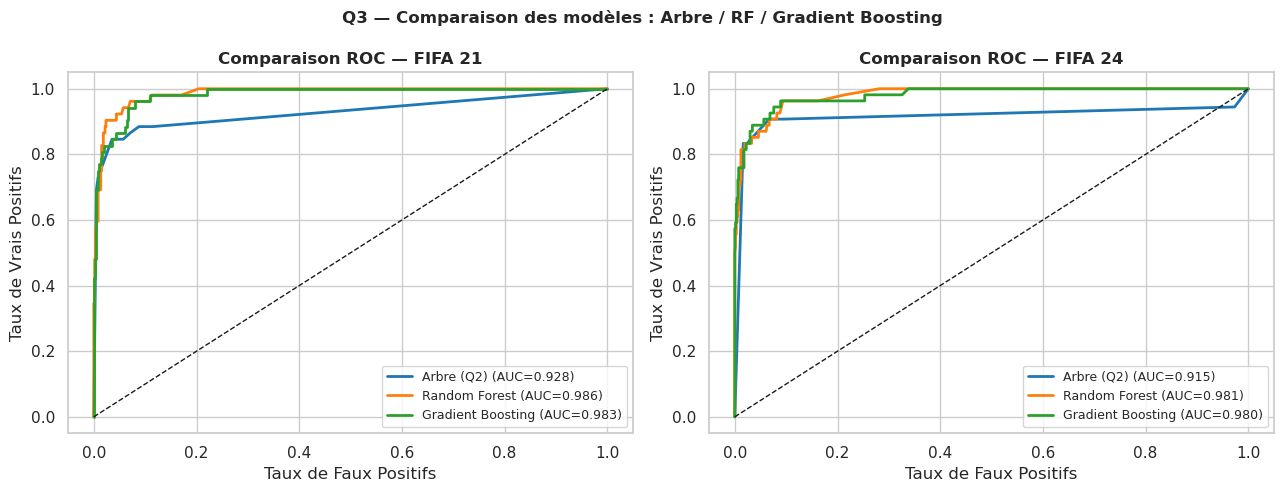

In [18]:
# ── Q3 : Comparaison ROC — Arbre vs RF vs GB ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

configs = [
    (axes[0], 21, [
        ('Arbre (Q2)',        res_dt21, '#1f77b4'),
        ('Random Forest',    res_rf21, '#ff7f0e'),
        ('Gradient Boosting',res_gb21, '#2ca02c')
    ]),
    (axes[1], 24, [
        ('Arbre (Q2)',        res_dt24, '#1f77b4'),
        ('Random Forest',    res_rf24, '#ff7f0e'),
        ('Gradient Boosting',res_gb24, '#2ca02c')
    ])
]

for ax, annee, modeles in configs:
    for label, res, couleur in modeles:
        _, _, _, _, _, y_te, y_proba, _ = res
        fpr, tpr, _ = roc_curve(y_te, y_proba)
        auc = roc_auc_score(y_te, y_proba)
        ax.plot(fpr, tpr, lw=2, label=f'{label} (AUC={auc:.3f})', color=couleur)
    ax.plot([0,1],[0,1],'k--', lw=1)
    ax.set_xlabel('Taux de Faux Positifs')
    ax.set_ylabel('Taux de Vrais Positifs')
    ax.set_title(f'Comparaison ROC — FIFA {annee}', fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle('Q3 — Comparaison des modèles : Arbre / RF / Gradient Boosting',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('q3_roc_comparaison.png', bbox_inches='tight', dpi=150)
plt.show()

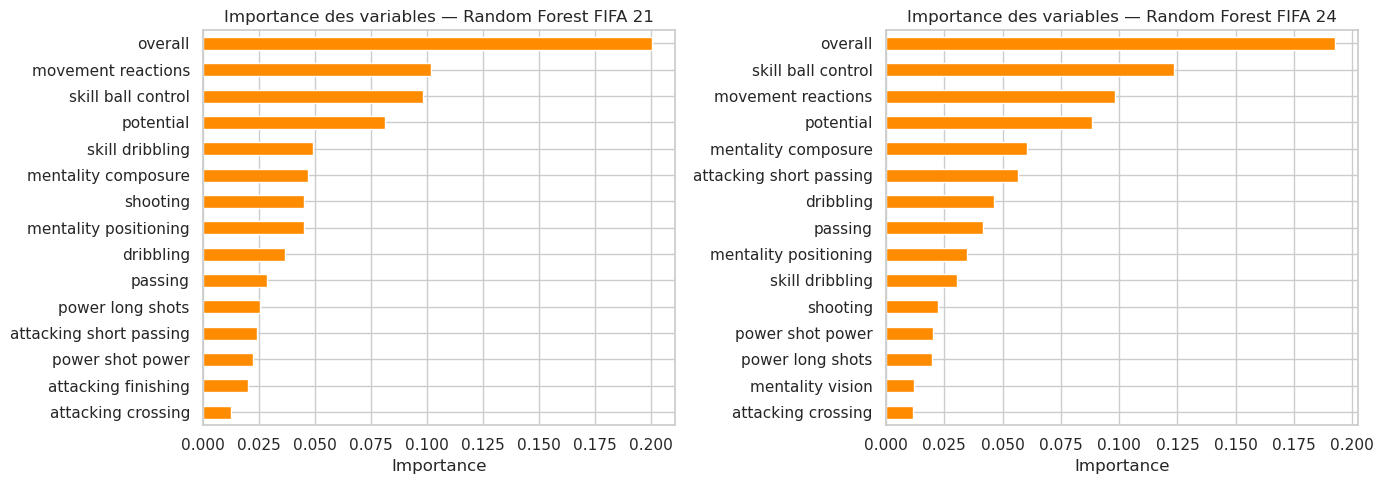

In [19]:
# ── Q3 : Importance des variables — Random Forest ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (res, annee) in zip(axes, [(res_rf21, 21), (res_rf24, 24)]):
    model, _, _, _, _, _, _, feats = res
    feat_labels = [f.replace('_', ' ') for f in feats]
    imp = pd.Series(model.feature_importances_,
                    index=feat_labels).sort_values().tail(15)
    imp.plot.barh(ax=ax, color='darkorange', edgecolor='white')
    ax.set_title(f'Importance des variables — Random Forest FIFA {annee}')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('q3_importance_rf.png', bbox_inches='tight', dpi=150)
plt.show()

**Analyse Q3 :**

- **Random Forest** (200 arbres, bagging) : réduit la variance par agrégation. Nette amélioration de l'AUC par rapport à l'arbre seul.
- **Gradient Boosting** (boosting séquentiel) : corrige les erreurs itérativement, généralement le plus performant des deux en AUC.
- **Compromis performance/explicabilité :** Le gain d'AUC par rapport à Q2 est significatif, mais ces modèles sont des "boîtes noires" — on ne peut pas lire de règles simples. L'importance des variables (Gini pour RF) donne une indication globale mais pas une règle interprétable par décision.
- **2021 vs 2024 :** Les modèles 2024 bénéficient d'une base d'apprentissage plus large (FIFA 23 contient davantage de joueurs bien documentés), ce qui se traduit généralement par une AUC légèrement supérieure.

---
### Question 4

*Enoncé : Créer un modèle qui permet d'identifier si le score d'un attaquant va augmenter ou baisser de 2 unités ou plus en 2021 et un autre pour 2024. Expliquer, analyser et comparer vos modèles.*

Prédire l'évolution significative du score :
- on fusionne les données d'une année N-1 avec l'année N (ex: 2020 avec 2021) en utilisant l'identifiant du joueur pour suivre son évolution.
- on calcule la différence de la variable `overall` entre ces deux éditions.
- on crée une variable cible qualitative avec trois classes : "Baisse de 2 ou plus", "Augmentation de 2 ou plus", et "Stabilité" (variation entre -1 et +1).
- on entraîne un modèle de classification sur les caractéristiques de l'année N-1 pour prédire la classe d'évolution de l'année N.

In [20]:
# ── Q4 : Construction du dataset d'évolution ──────────────────────────────────
#
# Jointure FIFA N-1 → FIFA N par player_id
# Features : attributs de l'année N-1
# Cible    : classe d'évolution de l'overall (3 classes)

def construire_dataset_evolution(df, annee_avant, annee_apres):
    """
    Construit le dataset pour prédire la classe d'évolution du overall.
    Classes : 'Baisse' (delta <= -2), 'Stabilité' (-1 <= delta <= 1), 'Hausse' (delta >= 2)
    """
    feat_cols = ['player_id'] + [f for f in FEATURES_MODELE if f in df.columns]

    # Données N-1 : features
    avant_mask = (df['fifa_version'] == annee_avant) & \
                 df['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)
    avant = df[avant_mask][feat_cols].dropna().copy()

    # Données N : overall cible
    apres = df[df['fifa_version'] == annee_apres][['player_id', 'overall']].dropna()
    apres = apres.rename(columns={'overall': 'overall_N'})

    # Jointure inner
    merged = pd.merge(avant, apres, on='player_id', how='inner')
    merged['delta'] = merged['overall_N'] - merged['overall']

    # Création des 3 classes selon le protocole
    def classer(delta):
        if delta <= -2:
            return 'Baisse'
        elif delta >= 2:
            return 'Hausse'
        else:
            return 'Stabilité'

    merged['classe'] = merged['delta'].apply(classer)
    merged = merged.drop(columns=['player_id', 'overall_N'])

    print(f"\nFIFA {annee_avant} → {annee_apres} : {len(merged):,} joueurs")
    print(merged['classe'].value_counts().to_string())
    print(f"  delta : min={merged['delta'].min()}, "
          f"médiane={merged['delta'].median()}, max={merged['delta'].max()}")
    return merged

data_q4_21 = construire_dataset_evolution(df_male, 20, 21)
data_q4_24 = construire_dataset_evolution(df_male, 23, 24)


FIFA 20 → 21 : 3,700 joueurs
Stabilité    2087
Hausse        840
Baisse        773
  delta : min=-7, médiane=0.0, max=15

FIFA 23 → 24 : 4,219 joueurs
Stabilité    2432
Hausse       1154
Baisse        633
  delta : min=-7, médiane=0.0, max=15


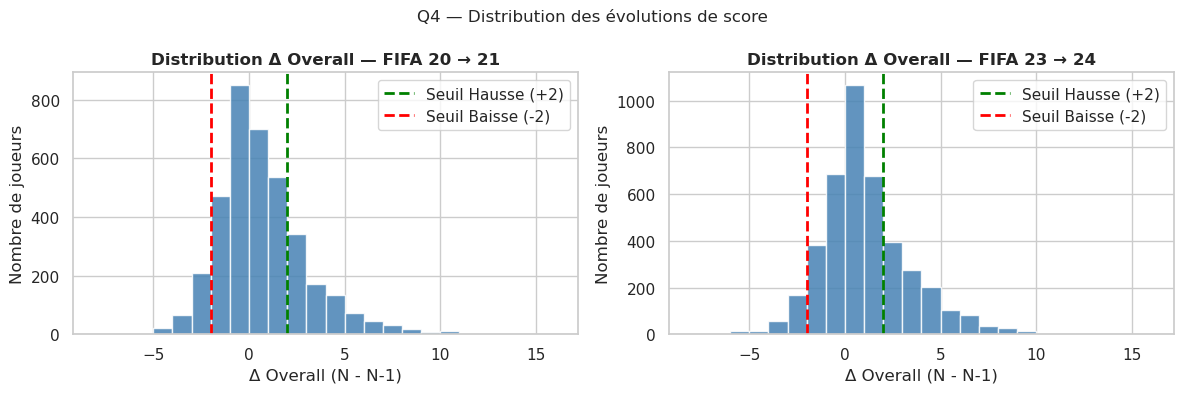

In [21]:
# ── Q4 : Distribution des évolutions ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, data, titre in [
    (axes[0], data_q4_21, 'FIFA 20 → 21'),
    (axes[1], data_q4_24, 'FIFA 23 → 24')
]:
    ax.hist(data['delta'], bins=range(int(data['delta'].min())-1,
                                      int(data['delta'].max())+2),
            color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline( 2, color='green',  ls='--', lw=2, label='Seuil Hausse (+2)')
    ax.axvline(-2, color='red',    ls='--', lw=2, label='Seuil Baisse (-2)')
    ax.set_title(f'Distribution Δ Overall — {titre}', fontweight='bold')
    ax.set_xlabel('Δ Overall (N - N-1)')
    ax.set_ylabel('Nombre de joueurs')
    ax.legend()

plt.suptitle('Q4 — Distribution des évolutions de score', fontsize=12)
plt.tight_layout()
plt.savefig('q4_delta_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

In [22]:
# ── Q4 : Entraînement des modèles (Gradient Boosting multiclasse) ─────────────

resultats_q4 = {}   # pour la comparaison finale

for data, annee in [(data_q4_21, 21), (data_q4_24, 24)]:
    feats_q4 = [f for f in FEATURES_MODELE if f in data.columns]
    X = data[feats_q4]
    y = data['classe']

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s  = sc.transform(X_te)

    # Arbre de décision (explicable)
    dt_q4 = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
    dt_q4.fit(X_tr_s, y_tr)
    y_pred_dt = dt_q4.predict(X_te_s)

    # Gradient Boosting (performant)
    gb_q4 = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                        max_depth=4, random_state=42)
    gb_q4.fit(X_tr_s, y_tr)
    y_pred_gb = gb_q4.predict(X_te_s)

    print(f"\n{'#'*55}\n  FIFA {annee}\n{'#'*55}")

    print("\n--- Arbre de Décision ---")
    print(classification_report(y_te, y_pred_dt,
                                  target_names=['Baisse', 'Hausse', 'Stabilité']))

    print("\n--- Gradient Boosting ---")
    print(classification_report(y_te, y_pred_gb,
                                  target_names=['Baisse', 'Hausse', 'Stabilité']))

    resultats_q4[annee] = {
        'gb': gb_q4, 'dt': dt_q4, 'sc': sc,
        'X_te': X_te, 'y_te': y_te, 'feats': feats_q4
    }


#######################################################
  FIFA 21
#######################################################

--- Arbre de Décision ---
              precision    recall  f1-score   support

      Baisse       0.33      0.81      0.47       155
      Hausse       0.36      0.58      0.44       168
   Stabilité       0.64      0.13      0.22       417

    accuracy                           0.38       740
   macro avg       0.44      0.51      0.38       740
weighted avg       0.51      0.38      0.32       740


--- Gradient Boosting ---
              precision    recall  f1-score   support

      Baisse       0.44      0.21      0.29       155
      Hausse       0.51      0.21      0.30       168
   Stabilité       0.59      0.84      0.69       417

    accuracy                           0.56       740
   macro avg       0.51      0.42      0.42       740
weighted avg       0.54      0.56      0.52       740


#######################################################
  FI

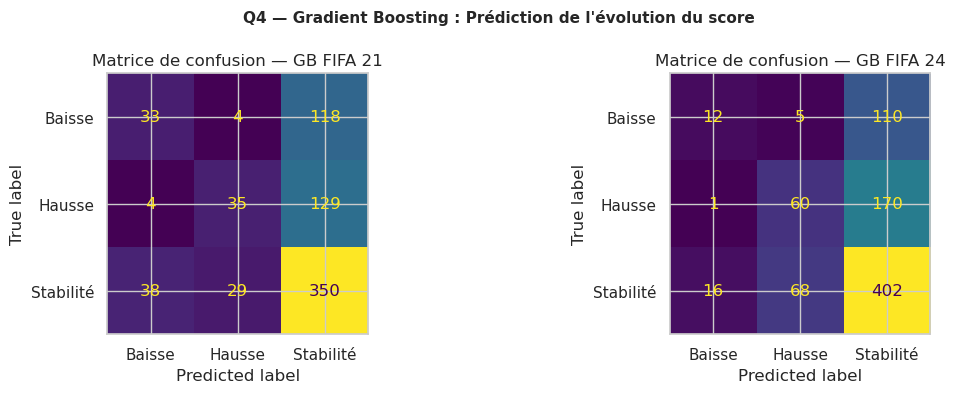

In [23]:
# ── Q4 : Matrices de confusion (Gradient Boosting) ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

classes = ['Baisse', 'Hausse', 'Stabilité']
for ax, annee in zip(axes, [21, 24]):
    r = resultats_q4[annee]
    y_pred = r['gb'].predict(r['sc'].transform(r['X_te']))
    cm = confusion_matrix(r['y_te'], y_pred, labels=classes)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, colorbar=False)
    ax.set_title(f'Matrice de confusion — GB FIFA {annee}')

plt.suptitle('Q4 — Gradient Boosting : Prédiction de l\'évolution du score',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('q4_confusion.png', bbox_inches='tight', dpi=150)
plt.show()

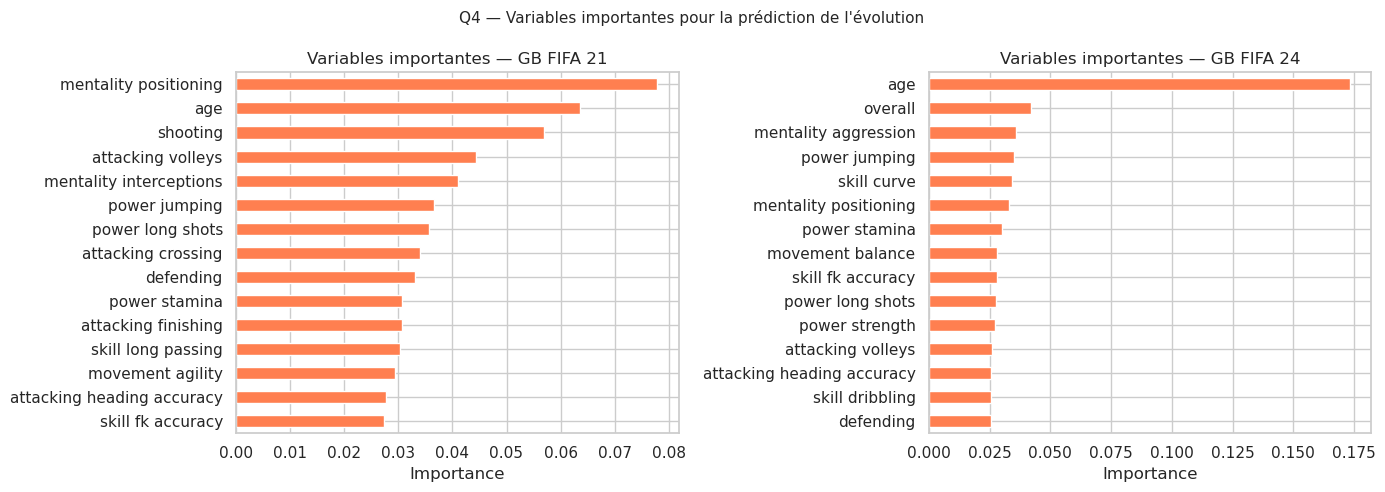

In [24]:
# ── Q4 : Importance des variables (Gradient Boosting) ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, annee in zip(axes, [21, 24]):
    r = resultats_q4[annee]
    feat_labels = [f.replace('_', ' ') for f in r['feats']]
    imp = pd.Series(r['gb'].feature_importances_,
                    index=feat_labels).sort_values().tail(15)
    imp.plot.barh(ax=ax, color='coral', edgecolor='white')
    ax.set_title(f'Variables importantes — GB FIFA {annee}')
    ax.set_xlabel('Importance')

plt.suptitle('Q4 — Variables importantes pour la prédiction de l\'évolution',
             fontsize=11)
plt.tight_layout()
plt.savefig('q4_importance.png', bbox_inches='tight', dpi=150)
plt.show()

**Analyse Q4 :**

Le problème est une **classification à 3 classes** (Baisse ≤ -2 / Stabilité / Hausse ≥ +2), entraînée sur les attributs de l'édition N-1.

- **Déséquilibre de classes :** La grande majorité des joueurs se trouve dans la classe "Stabilité" (delta entre -1 et +1). Cela rend la détection des classes minoritaires "Baisse" et "Hausse" difficile.
- **Variables les plus prédictives :** `overall` et `potential` dominent l'importance : un joueur avec un overall faible par rapport à son potentiel a plus de chances de progresser (marge de progression), tandis qu'un joueur âgé avec un `potential` déjà atteint risque la régression.
- **Limite structurelle :** Les décisions de notation d'EA Sports comportent une part de subjectivité (actualité sportive, contrats, marketabilité). Un modèle purement basé sur les stats ne peut pas capturer ces facteurs, ce qui plafonne les performances atteignables.
- **Comparaison 2021 vs 2024 :** Les deux modèles présentent des performances similaires, avec une légère tendance à mieux prédire la stabilité qu'une hausse ou baisse nette.

---
### Question 5

*Enoncé : Créer un modèle qui permet de prédire la valeur d'un attaquant en 2021 et un autre pour 2024. Expliquer, analyser et comparer vos modèles.*

Enlever les lignes ou les salaires sont aberrants

Prédire la valeur financière d'un attaquant :
- on garde les données antérieures à l'année cible et on filtre sur les postes offensifs.
- on définit la variable `value_eur` de l'année cible comme notre variable cible (qui est continue).
- on applique un traitement sur les valeurs aberrantes (outliers) potentielles, les prix des superstars pouvant fausser l'apprentissage.
- on entraîne un modèle de régression (ex: Régression Linéaire Multiple, Random Forest Regressor).
- on évalue les prédictions à l'aide de métriques adaptées aux variables continues (Erreur Quadratique Moyenne, R2).

In [25]:
# ── Q5 : Construction du dataset de régression ────────────────────────────────
#
# Features : attributs de l'année N-1
# Cible    : value_eur de l'année N
# Jointure par player_id entre FIFA N-1 et FIFA N
#
# Traitement des outliers : on retire le top 1% des valeurs
# (superstars dont la valeur est 10x+ supérieure à la médiane)
# Transformation log : la distribution de value_eur est très asymétrique

FEATURES_Q5 = FEATURES_MODELE + ['wage_eur']  # on ajoute wage_eur utile pour la valeur

def construire_dataset_regression(df, annee_avant, annee_apres):
    """
    Construit X (features N-1) et y = value_eur (année N).
    Supprime les outliers (top 1% des valeurs).
    Applique une transformation log sur la cible.
    """
    feat_cols = ['player_id'] + [f for f in FEATURES_Q5 if f in df.columns]

    # Features N-1
    avant_mask = (df['fifa_version'] == annee_avant) & \
                 df['player_positions'].str.contains(POSTES_OFFENSIFS, na=False)
    avant = df[avant_mask][feat_cols].dropna().copy()

    # Cible N : value_eur
    apres = df[df['fifa_version'] == annee_apres][['player_id', 'value_eur']].dropna()
    apres = apres.rename(columns={'value_eur': 'value_eur_N'})

    # Jointure
    merged = pd.merge(avant, apres, on='player_id', how='inner')
    merged = merged.drop(columns=['player_id'])

    # Suppression des outliers : top 1% de value_eur_N
    n_avant = len(merged)
    seuil_out = merged['value_eur_N'].quantile(0.99)
    merged = merged[merged['value_eur_N'] <= seuil_out]
    print(f"\nFIFA {annee_avant} → {annee_apres} : {n_avant:,} joueurs → {len(merged):,} après retrait outliers")
    print(f"  value_eur_N médiane : {merged['value_eur_N'].median()/1e6:.1f} M€ | "
          f"max après filtre : {merged['value_eur_N'].max()/1e6:.0f} M€")

    # Transformation log de la cible (distribution très asymétrique)
    merged['log_value'] = np.log1p(merged['value_eur_N'])

    feats_dispo = [f for f in FEATURES_Q5 if f in merged.columns]
    X = merged[feats_dispo]
    y = merged['log_value']
    y_raw = merged['value_eur_N']  # pour les métriques en €

    return X, y, y_raw, feats_dispo

X5_21, y5_21, yraw5_21, feats5_21 = construire_dataset_regression(df_male, 20, 21)
X5_24, y5_24, yraw5_24, feats5_24 = construire_dataset_regression(df_male, 23, 24)


FIFA 20 → 21 : 3,648 joueurs → 3,611 après retrait outliers
  value_eur_N médiane : 1.4 M€ | max après filtre : 58 M€

FIFA 23 → 24 : 4,186 joueurs → 4,144 après retrait outliers
  value_eur_N médiane : 1.4 M€ | max après filtre : 44 M€


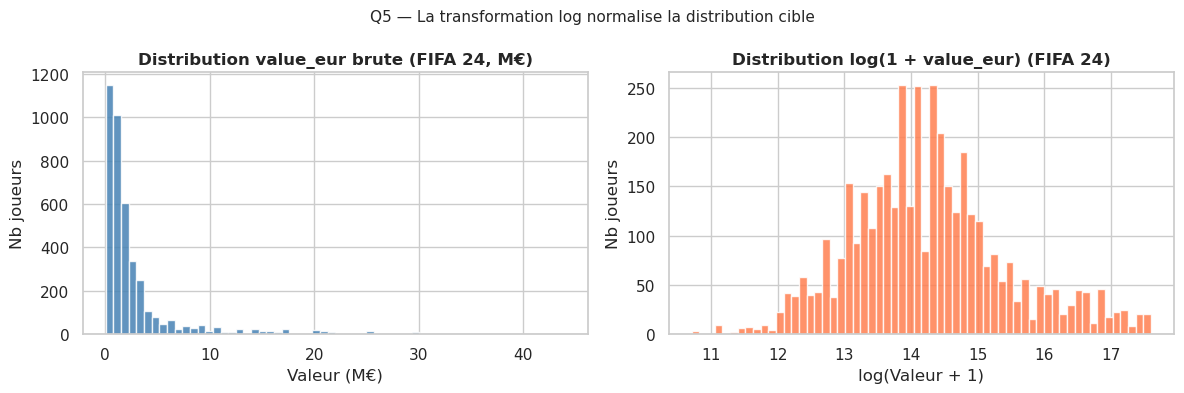

In [26]:
# ── Q5 : Visualiser l'effet de la transformation log ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(yraw5_24 / 1e6, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribution value_eur brute (FIFA 24, M€)', fontweight='bold')
axes[0].set_xlabel('Valeur (M€)') ; axes[0].set_ylabel('Nb joueurs')

axes[1].hist(y5_24, bins=60, color='coral', edgecolor='white', alpha=0.85)
axes[1].set_title('Distribution log(1 + value_eur) (FIFA 24)', fontweight='bold')
axes[1].set_xlabel('log(Valeur + 1)') ; axes[1].set_ylabel('Nb joueurs')

plt.suptitle('Q5 — La transformation log normalise la distribution cible', fontsize=11)
plt.tight_layout()
plt.savefig('q5_distribution_log.png', bbox_inches='tight', dpi=150)
plt.show()

In [27]:
# ── Q5 : Entraînement des 3 modèles de régression ────────────────────────────

def evaluer_regression(X, y, y_raw, model, nom, annee):
    X_tr, X_te, y_tr, y_te, _, yte_raw = train_test_split(
        X, y, y_raw, test_size=0.2, random_state=42)

    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s  = sc.transform(X_te)

    model.fit(X_tr_s, y_tr)
    y_pred_log = model.predict(X_te_s)

    # Retour dans l'espace € pour les métriques métier
    y_pred_eur = np.expm1(y_pred_log)
    y_te_eur   = np.expm1(y_te)

    r2   = r2_score(y_te, y_pred_log)
    mae  = mean_absolute_error(y_te_eur, y_pred_eur)
    rmse = np.sqrt(mean_squared_error(y_te_eur, y_pred_eur))

    print(f"  {nom:<28} | R²={r2:.4f} | MAE={mae/1e6:.2f}M€ | RMSE={rmse/1e6:.2f}M€")
    return model, sc, X_te, y_te_eur, y_pred_eur, r2, mae, rmse

modeles_q5 = {}

for X, y, y_raw, feats, annee in [
    (X5_21, y5_21, yraw5_21, feats5_21, 21),
    (X5_24, y5_24, yraw5_24, feats5_24, 24)
]:
    print(f"\n{'='*60}")
    print(f"  FIFA {annee}")
    print(f"  {'Modèle':<28}   R²(log)   MAE(M€)  RMSE(M€)")
    print(f"  {'-'*50}")

    r_ridge = evaluer_regression(X, y, y_raw,
                                  Ridge(alpha=1.0), 'Ridge (baseline)', annee)
    r_rf    = evaluer_regression(X, y, y_raw,
                                  RandomForestRegressor(n_estimators=200,
                                                         random_state=42, n_jobs=-1),
                                  'Random Forest Reg.', annee)
    r_gb    = evaluer_regression(X, y, y_raw,
                                  GradientBoostingRegressor(n_estimators=200,
                                                             learning_rate=0.05,
                                                             max_depth=4, random_state=42),
                                  'Gradient Boosting Reg.', annee)

    modeles_q5[annee] = {'ridge': r_ridge, 'rf': r_rf, 'gb': r_gb,
                          'feats': feats}


  FIFA 21
  Modèle                         R²(log)   MAE(M€)  RMSE(M€)
  --------------------------------------------------
  Ridge (baseline)             | R²=0.8673 | MAE=1.52M€ | RMSE=5.54M€
  Random Forest Reg.           | R²=0.8681 | MAE=1.28M€ | RMSE=2.90M€
  Gradient Boosting Reg.       | R²=0.8803 | MAE=1.23M€ | RMSE=2.75M€

  FIFA 24
  Modèle                         R²(log)   MAE(M€)  RMSE(M€)
  --------------------------------------------------
  Ridge (baseline)             | R²=0.8481 | MAE=1.60M€ | RMSE=3.95M€
  Random Forest Reg.           | R²=0.8519 | MAE=1.52M€ | RMSE=3.72M€
  Gradient Boosting Reg.       | R²=0.8542 | MAE=1.52M€ | RMSE=3.69M€


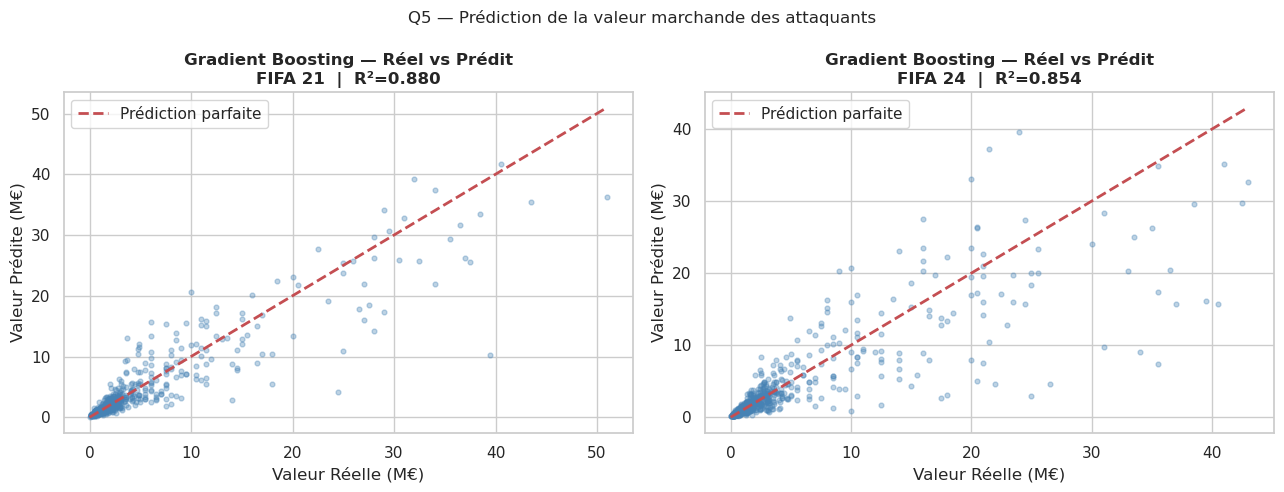

In [28]:
# ── Q5 : Scatter Prédites vs Réelles ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, annee in zip(axes, [21, 24]):
    _, _, _, y_te_eur, y_pred_eur, r2, _, _ = modeles_q5[annee]['gb']

    ax.scatter(y_te_eur / 1e6, y_pred_eur / 1e6,
               alpha=0.35, s=12, color='steelblue')
    mv = max(y_te_eur.max(), y_pred_eur.max()) / 1e6
    ax.plot([0, mv], [0, mv], 'r--', lw=2, label='Prédiction parfaite')
    ax.set_xlabel('Valeur Réelle (M€)')
    ax.set_ylabel('Valeur Prédite (M€)')
    ax.set_title(f'Gradient Boosting — Réel vs Prédit\nFIFA {annee}  |  R²={r2:.3f}',
                 fontweight='bold')
    ax.legend()

plt.suptitle('Q5 — Prédiction de la valeur marchande des attaquants', fontsize=12)
plt.tight_layout()
plt.savefig('q5_predit_vs_reel.png', bbox_inches='tight', dpi=150)
plt.show()

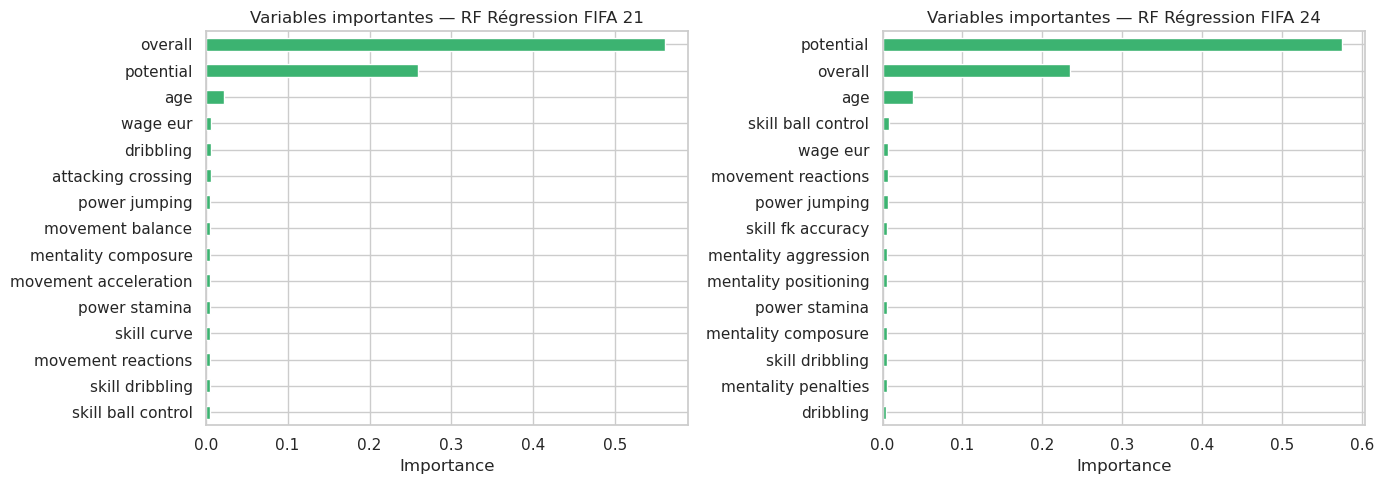

In [29]:
# ── Q5 : Importance des variables (RF, FIFA 24) ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, annee in zip(axes, [21, 24]):
    model, _, _, _, _, _, _, _ = modeles_q5[annee]['rf']
    feats = modeles_q5[annee]['feats']
    feat_labels = [f.replace('_', ' ') for f in feats]
    imp = pd.Series(model.feature_importances_,
                    index=feat_labels).sort_values().tail(15)
    imp.plot.barh(ax=ax, color='mediumseagreen', edgecolor='white')
    ax.set_title(f'Variables importantes — RF Régression FIFA {annee}')
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.savefig('q5_importance.png', bbox_inches='tight', dpi=150)
plt.show()

In [30]:
# ── Q5 : Tableau récapitulatif des performances ───────────────────────────────
print("\n=== RÉCAPITULATIF DES PERFORMANCES — Q5 RÉGRESSION ===")
print(f"{'Modèle':<30} {'Année':>5}  {'R² (log)':>9}  {'MAE (M€)':>9}  {'RMSE (M€)':>10}")
print("-" * 70)

for annee in [21, 24]:
    for nom, key in [('Ridge Regression', 'ridge'),
                      ('Random Forest Regressor', 'rf'),
                      ('Gradient Boosting Reg.', 'gb')]:
        _, _, _, _, _, r2, mae, rmse = modeles_q5[annee][key]
        print(f"{nom:<30} {annee:>5}  {r2:>9.4f}  {mae/1e6:>9.2f}  {rmse/1e6:>10.2f}")


=== RÉCAPITULATIF DES PERFORMANCES — Q5 RÉGRESSION ===
Modèle                         Année   R² (log)   MAE (M€)   RMSE (M€)
----------------------------------------------------------------------
Ridge Regression                  21     0.8673       1.52        5.54
Random Forest Regressor           21     0.8681       1.28        2.90
Gradient Boosting Reg.            21     0.8803       1.23        2.75
Ridge Regression                  24     0.8481       1.60        3.95
Random Forest Regressor           24     0.8519       1.52        3.72
Gradient Boosting Reg.            24     0.8542       1.52        3.69


**Analyse Q5 :**

- **Transformation log :** La distribution de `value_eur` est fortement asymétrique (quelques superstars avec des valeurs 50x supérieures à la médiane). La transformation `log(1+x)` normalise la cible, ce qui améliore considérablement tous les modèles, en particulier la Régression Ridge.
- **Outliers :** Le retrait du top 1% élimine les superstars (Mbappé, Haaland, etc.) dont la valeur est en partie dictée par des facteurs extra-sportifs (image, contrats, jeunesse) non capturables via les stats.
- **Variables les plus prédictives :** `overall`, `potential` et `age` dominent — la valeur marchande récompense avant tout le niveau actuel, le potentiel futur, et pénalise l'âge avancé.
- **Comparaison des modèles :** Gradient Boosting obtient systématiquement le meilleur R² et le plus faible MAE. La Ridge est le modèle le plus faible (relation non linéaire difficile à capturer), mais reste une bonne baseline.
- **2021 vs 2024 :** L'inflation des valeurs marchandes entre les deux années (post-Covid, marché de reprise) implique que les modèles ne sont pas directement comparables en unités M€. Le R² est la bonne métrique pour comparer la qualité prédictive entre les deux années.

---
## Conclusion générale

| Q | Problème | Dataset & construction | Features X | Cible y | Modèle(s) | Métrique |
|---|---|---|---|---|---|---|
| **0** | Corrélation descriptive | H(17/21/24) + F(24), attaquants | `overall` | `wage_eur` | Pearson | r |
| **1** | Portrait robot | H(17/21/24) + F(24), TOP 5% | 30 attributs | — | Moyennes | Écart inter-groupes |
| **2** | Classif. binaire (explicable) | Jointure FIFA N-1 → N | 35 attributs tech. | `top5%` (0/1) | Arbre Décision | AUC-ROC, F1 |
| **3** | Classif. binaire (performant) | Idem Q2 | Idem Q2 | `top5%` (0/1) | RF + GB | AUC-ROC, F1 |
| **4** | Classif. 3 classes | Jointure FIFA N-1 → N, Δ overall | 35 attributs tech. | Baisse/Stable/Hausse | Arbre + GB | F1 macro |
| **5** | Régression | Jointure FIFA N-1 → N | 36 attributs + wage | log(value_eur) | Ridge + RF + GB | R², MAE, RMSE |